# P1: Ridge e LightGBM — quando o modelo erra?

**Projeto:** previsão do tempo de viagem de ônibus entre paradas consecutivas, linha 415 (Usina–Leblon), Rio de Janeiro, 25/01 a 21/03/2019.

**Responsável:** Pessoa 1. A análise exploratória temporal está em `01_eda_temporal.ipynb`.

1. Configuração, preparação e split
2. Baseline
3. Ridge (modelo linear)
4. LightGBM (ensemble por boosting)
5. Comparação e erro ao longo do tempo
6. Experimento extra: um modelo por grupo vs. um modelo único

Tudo usa o contrato de `src/common.py` (`prepare`, `split`, `build_features`, `evaluate`), o mesmo do notebook da P2, então as métricas dos dois notebooks são comparáveis.

## 1. Configuração, preparação e split

In [1]:
import sys
import time
import warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Arquivo público no Google Drive (derivado de datasets públicos do Kaggle).
# Baixado por link com gdown: funciona em qualquer conta, sem montar o Drive.
SEGMENTS_FILE_ID = "1tLj2N9EPlnRzXaLENXVkb6k_4zGxi56S"

if IN_COLAB:
    import gdown

    DATA_DIR = Path("/content/dados")
    SEGMENTS_PATH = DATA_DIR / "7-segments" / "segments_415_v0.parquet"
    SEGMENTS_PATH.parent.mkdir(parents=True, exist_ok=True)
    if not SEGMENTS_PATH.exists():
        gdown.download(id=SEGMENTS_FILE_ID, output=str(SEGMENTS_PATH), quiet=False)
    if not Path("/content/onibus-ia").exists():
        !git clone -q https://github.com/figdavi/onibus-ia.git /content/onibus-ia
    else:
        !git -C /content/onibus-ia pull -q
    sys.path.insert(0, "/content/onibus-ia/src")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA_DIR = ROOT / "dados"
    sys.path.insert(0, str(ROOT / "src"))
    SEGMENTS_PATH = next(p for p in [DATA_DIR / "7-segments" / "segments_415_v0.parquet",
                                     ROOT / "segments_415_v0.parquet"] if p.exists())
    DATA_DIR.mkdir(exist_ok=True)

print(SEGMENTS_PATH.name)

segments_415_v0.parquet


In [2]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import common

warnings.filterwarnings("ignore", message=".*eval_set.*")
pd.set_option("display.precision", 2)
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
SEED = 42

In [3]:
raw = pd.read_parquet(SEGMENTS_PATH)
raw["departure_ts"] = pd.to_datetime(raw["departure_ts"])

df = common.prepare(raw)
print(df.attrs["prepare_report"])

train, val, test = common.split(df)
for name, part in [("treino", train), ("validação", val), ("teste", test)]:
    print(f"{name:10s} {len(part):>8,} trechos  {part['service_date'].min()} a {part['service_date'].max()}")

# reference=train: as medianas por trecho vêm só do treino (sem vazamento)
X_train, y_train = common.build_features(train, reference=train)
X_val, y_val = common.build_features(val, reference=train)
X_test, y_test = common.build_features(test, reference=train)
X_train.shape

{'rows_in': 370784, 'sparse_days': 562, 'implausible_speed': 2031, 'too_short': 88, 'rows_out': 368103}
treino      253,819 trechos  2019-01-25 a 2019-03-03
validação    19,668 trechos  2019-03-04 a 2019-03-07
teste        78,918 trechos  2019-03-11 a 2019-03-20


(253819, 17)

**Split temporal.** Treino no passado (até 03/03), validação em 04–07/03 e teste em 11–20/03, sem embaralhar: é assim que o modelo seria usado na prática. A validação cai na semana do Carnaval, que a EDA mostrou ser atípica (mais rápida, metade da frota). Por isso ela serve para escolher hiperparâmetros, mas os números que valem são os do **teste**.

## 2. Baseline: mediana por sentido, parada, hora e fim de semana

In [4]:
results = {}
baseline = common.MedianBaseline().fit(X_train, y_train)
results["Baseline (mediana)"] = common.evaluate(baseline, X_test, y_test)
results["Baseline (mediana)"]

{'MAE_s': 19.13, 'RMSE_s': 31.49, 'R2': 0.6357, 'n': 78918}

## 3. Ridge (regressão linear com regularização L2)

O Ridge só soma efeitos: `tempo = w1·x1 + w2·x2 + …`. A EDA mostrou que a relação com a hora tem degraus e um pico às 17–18h, e que a curva muda com o tipo de dia. Testamos três versões, da mais ingênua à mais ajustada:

| Versão | O que muda |
|---|---|
| A. Numérico | As 17 features como números, padronizadas. `stop_seq` e `hour` entram como se fossem quantidades. |
| B. One-hot | Um coeficiente por **trecho** (sentido × parada) e um por **hora × tipo de dia** (útil, sábado, domingo, Carnaval). |
| C. One-hot + log | Igual a B, mas prevendo `log(tempo)` e com distância, lags e ritmo da viagem em log. Erros passam a ser relativos, e a cauda longa do alvo pesa menos. |

O `alpha` (força da regularização) é escolhido pelo MAE na validação.

In [5]:
def add_ridge_columns(X):
    """Colunas categóricas e em log usadas só pelo Ridge."""
    out = X.copy()
    out["segment"] = (out["direction_Usina"].astype(int).astype(str) + "_"
                      + out["stop_seq"].astype(int).astype(str))
    kind = np.select(
        [out["is_carnival"] == 1, out["day_of_week"] == 6, out["day_of_week"] == 5],
        ["carnaval", "domingo", "sabado"], default="util")
    out["hour_kind"] = out["hour"].astype(int).astype(str) + "_" + kind
    out["log_distance_m"] = np.log(out["distance_m"])
    out["log_lag_previous_segment_s"] = np.log(out["lag_previous_segment_s"])
    out["log_lag_previous_bus_s"] = np.log(out["lag_previous_bus_s"])
    out["log_recent_buses_mean_s"] = np.log(out["recent_buses_mean_s"])
    out["log_segment_median_s"] = np.log(out["segment_median_s"])
    out["log_trip_pace_last"] = np.log(out["trip_pace_last"])
    out["log_trip_pace_mean"] = np.log(out["trip_pace_mean"])
    return out

R_train, R_val, R_test = (add_ridge_columns(x) for x in (X_train, X_val, X_test))

CATEGORICAL = ["segment", "hour_kind"]
NUMERIC = ["distance_m", "lag_previous_segment_s", "lag_previous_bus_s", "minutes_since_previous_bus",
           "recent_buses_mean_s", "segment_median_s", "trip_pace_last", "trip_pace_mean"]
NUMERIC_LOG = ["log_distance_m", "log_lag_previous_segment_s", "log_lag_previous_bus_s",
               "minutes_since_previous_bus", "log_recent_buses_mean_s", "log_segment_median_s",
               "log_trip_pace_last", "log_trip_pace_mean"]

def ridge_onehot(alpha, numeric, log_target):
    columns = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAL),
        # add_indicator: uma coluna 0/1 dizendo "o lag não existia" (1ª parada da viagem)
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                              StandardScaler()), numeric),
    ])
    model = make_pipeline(columns, Ridge(alpha=alpha))
    if log_target:
        return TransformedTargetRegressor(model, func=np.log, inverse_func=np.exp)
    return model

VARIANTS = {
    "Ridge A (numérico)": (lambda a: common.scaled(Ridge(alpha=a)), X_train, X_val, X_test),
    "Ridge B (one-hot)": (lambda a: ridge_onehot(a, NUMERIC, False), R_train, R_val, R_test),
    "Ridge C (one-hot + log)": (lambda a: ridge_onehot(a, NUMERIC_LOG, True), R_train, R_val, R_test),
}
ALPHAS = [0.1, 1, 10, 100]

ridge_models, search = {}, []
for name, (make, Xtr, Xva, Xte) in VARIANTS.items():
    fitted = {a: make(a).fit(Xtr, y_train) for a in ALPHAS}
    val_mae = {a: common.evaluate(m, Xva, y_val)["MAE_s"] for a, m in fitted.items()}
    best = min(val_mae, key=val_mae.get)
    ridge_models[name] = (fitted[best], Xte)
    results[name] = common.evaluate(fitted[best], Xte, y_test)
    search.append({"versão": name, **{f"val MAE α={a}": v for a, v in val_mae.items()},
                   "α escolhido": best, "teste MAE": results[name]["MAE_s"],
                   "teste RMSE": results[name]["RMSE_s"]})
pd.DataFrame(search).set_index("versão")

,val MAE α=0.1,val MAE α=1,val MAE α=10,val MAE α=100,α escolhido,teste MAE,teste RMSE
versão,,,,,,,
Ridge A (numérico),16.74,16.74,16.74,16.74,0.1,19.04,30.80
Ridge B (one-hot),16.92,16.92,16.89,16.74,100.0,19.05,30.56
Ridge C (one-hot + log),15.29,15.29,15.28,15.24,100.0,18.09,31.42


**Leitura.**
- As versões A e B empatam com o baseline. A feature `segment_median_s` já entrega o tempo típico de cada trecho como um número, então tratar `stop_seq` como quantidade deixa de atrapalhar, e o one-hot de trecho acrescenta pouco.
- A versão C é a melhor, cerca de 5% abaixo do baseline. Em log, os efeitos viram multiplicativos: o pico deixa todos os trechos X% mais lentos, em vez de somar os mesmos segundos a um trecho de 100 m e a um de 3 km. Prever em log também aproxima a previsão da mediana, que é o que o MAE premia. O preço aparece no RMSE, que piora.
- O `alpha` quase não muda o resultado: com ~250 mil linhas e ~200 colunas, o modelo não está sobreajustando. O limite do Ridge aqui é de **forma** (linearidade), não de variância.

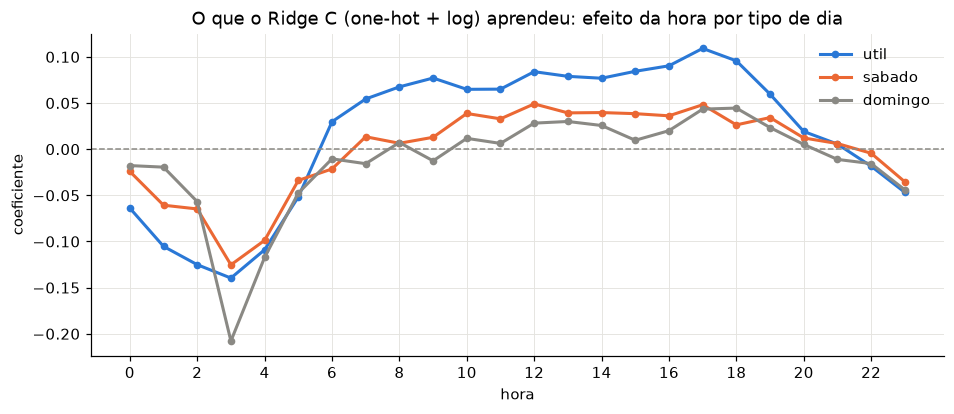

In [6]:
best_ridge_name = min(VARIANTS, key=lambda n: results[n]["MAE_s"])
best_ridge, _ = ridge_models[best_ridge_name]
pipeline = best_ridge.regressor_ if hasattr(best_ridge, "regressor_") else best_ridge
names = pipeline[0].get_feature_names_out()
coefs = pd.Series(pipeline[-1].coef_, index=names)

hour_coefs = coefs[coefs.index.str.startswith("cat__hour_kind_")]
labels = hour_coefs.index.str.replace("cat__hour_kind_", "")
hour_table = pd.DataFrame({
    "hour": labels.str.split("_").str[0],
    "kind": labels.str.split("_").str[1],
    "coef": hour_coefs.to_numpy(),
})
hour_table = hour_table[hour_table["hour"].str.isdigit()]
hour_table = hour_table.assign(hour=hour_table["hour"].astype(int)).pivot(
    index="hour", columns="kind", values="coef").sort_index()

fig, ax = plt.subplots(figsize=(10, 3.8))
for kind, color in [("util", BLUE), ("sabado", ORANGE), ("domingo", GRAY)]:
    if kind in hour_table:
        ax.plot(hour_table.index, hour_table[kind], marker="o", ms=4, lw=2, color=color, label=kind)
ax.axhline(0, color=GRAY, lw=1, ls="--")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hora"); ax.set_ylabel("coeficiente")
ax.set_title(f"O que o {best_ridge_name} aprendeu: efeito da hora por tipo de dia")
ax.legend(frameon=False)
plt.show()

Os coeficientes reproduzem a curva da EDA: efeito negativo de madrugada, patamar durante o dia e pico no fim da tarde em dia útil, com sábado e domingo abaixo. No modelo em log, um coeficiente de 0,1 significa cerca de 10% a mais de tempo.

## 4. LightGBM (ensemble por boosting)

Árvores treinadas em sequência, cada uma corrigindo o erro das anteriores. Diferente do Ridge, as árvores criam interações sozinhas (trecho × hora × lag) e aceitam os lags vazios sem imputação.

Testamos duas funções de perda:
- **L2** (erro quadrático), o padrão;
- **L1** (erro absoluto), que otimiza diretamente o MAE, a nossa métrica principal.

O número de árvores é definido por *early stopping* na validação: o treino para quando o MAE de validação fica 100 rodadas sem melhorar.

In [7]:
LGBM_PARAMS = dict(
    n_estimators=3000, learning_rate=0.05, num_leaves=63, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1,
)

def fit_lgbm(Xtr, ytr, Xva, yva, objective):
    curve = {}
    model = lgb.LGBMRegressor(objective=objective, **LGBM_PARAMS)
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="l1",
              callbacks=[lgb.early_stopping(100, verbose=False), lgb.record_evaluation(curve)])
    return model, curve["valid_0"]["l1"]

lgbm_models, curves = {}, {}
for objective, label in [("l2", "LightGBM (L2)"), ("l1", "LightGBM (L1)")]:
    model, curves[label] = fit_lgbm(X_train, y_train, X_val, y_val, objective)
    lgbm_models[label] = model
    results[label] = common.evaluate(model, X_test, y_test)
    print(f"{label}: {model.best_iteration_} árvores, {results[label]}")

LightGBM (L2): 71 árvores, {'MAE_s': 17.51, 'RMSE_s': 28.82, 'R2': 0.695, 'n': 78918}


LightGBM (L1): 598 árvores, {'MAE_s': 16.35, 'RMSE_s': 29.11, 'R2': 0.6888, 'n': 78918}


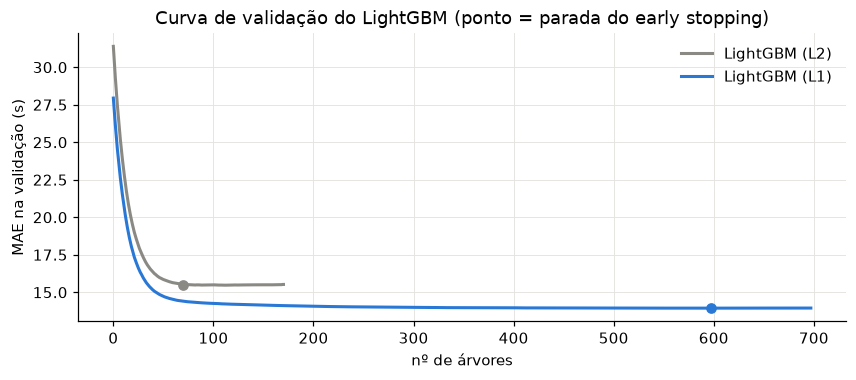

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for (label, curve), color in zip(curves.items(), [GRAY, BLUE]):
    ax.plot(curve, color=color, lw=2, label=label)
    ax.scatter([lgbm_models[label].best_iteration_ - 1], [min(curve)], color=color, zorder=3)
ax.set_xlabel("nº de árvores"); ax.set_ylabel("MAE na validação (s)")
ax.set_title("Curva de validação do LightGBM (ponto = parada do early stopping)")
ax.legend(frameon=False)
plt.show()

**Leitura.** A perda L1 dá o menor MAE; a L2 fica com RMSE parecido e MAE pior, porque persegue a média de uma distribuição com cauda longa. A versão L2 para cedo: a validação é a semana do Carnaval, e depois de poucas árvores o modelo começa a aprender detalhes de dias normais que não valem para ela. Ficamos com a **L1** como modelo final da P1.

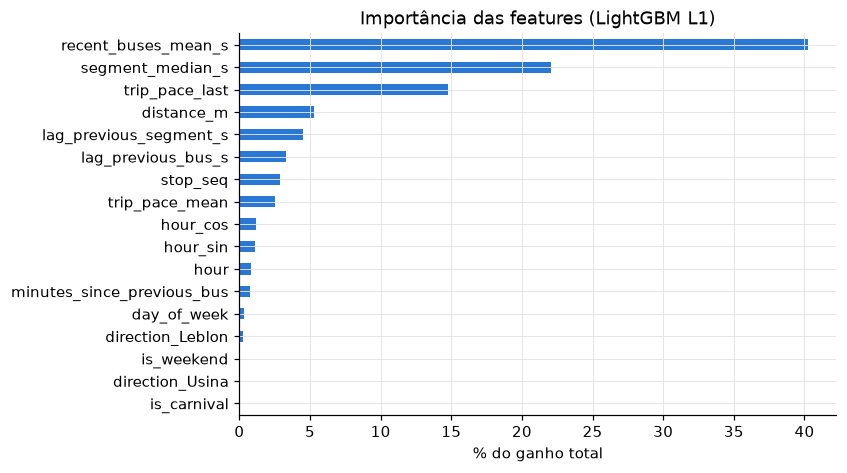

In [9]:
lgbm = lgbm_models["LightGBM (L1)"]
gain = pd.Series(lgbm.booster_.feature_importance("gain"), index=X_train.columns)
gain = (100 * gain / gain.sum()).sort_values()
ax = gain.plot.barh(figsize=(7, 4.5), color=BLUE)
ax.set_xlabel("% do ganho total")
ax.set_title("Importância das features (LightGBM L1)")
plt.show()

### Quanto vale o trânsito em tempo real?

Seis features trazem informação de **trânsito em tempo real**: o tempo do trecho anterior na mesma viagem, o tempo do mesmo trecho pelo ônibus anterior e a média dos últimos 3 ônibus, o intervalo desde o ônibus anterior e o ritmo da viagem (quanto ela está mais lenta ou mais rápida que o normal, no último trecho e na média). Treinamos o mesmo LightGBM sem elas para medir quanto contribuem; a mediana histórica do trecho continua como feature.

In [10]:
# Tudo o que depende do trânsito do dia; segment_median_s (perfil histórico) fica.
LAGS = ["lag_previous_segment_s", "lag_previous_bus_s", "minutes_since_previous_bus",
        "recent_buses_mean_s", "trip_pace_last", "trip_pace_mean"]
static = [c for c in X_train.columns if c not in LAGS]
lgbm_static, _ = fit_lgbm(X_train[static], y_train, X_val[static], y_val, "l1")
results["LightGBM (L1, sem tempo real)"] = common.evaluate(lgbm_static, X_test[static], y_test)
pd.DataFrame({k: results[k] for k in ["Baseline (mediana)", "LightGBM (L1, sem tempo real)", "LightGBM (L1)"]}).T

,MAE_s,RMSE_s,R2,n
Baseline (mediana),19.13,31.49,0.64,78918.0
"LightGBM (L1, sem tempo real)",20.44,35.58,0.54,78918.0
LightGBM (L1),16.35,29.11,0.69,78918.0


**Leitura.** Sem essas features, o LightGBM só tem calendário, posição e a mediana histórica do trecho, a mesma informação do baseline, e não consegue superá-lo. Todo o ganho sobre o baseline vem de saber como está o trânsito **agora**. O calendário diz o que é típico; as features de tempo real dizem o que está acontecendo hoje.

## 5. Comparação e erro ao longo do tempo

In [11]:
table = common.metrics_table(results)
table["vs. baseline (%)"] = 100 * (table["MAE_s"] / results["Baseline (mediana)"]["MAE_s"] - 1)
table.to_csv(DATA_DIR / "metricas_p1.csv")
table

,MAE_s,RMSE_s,R2,n,vs. baseline (%)
LightGBM (L1),16.35,29.11,0.69,78918.0,-14.53
LightGBM (L2),17.51,28.82,0.69,78918.0,-8.47
Ridge C (one-hot + log),18.09,31.42,0.64,78918.0,-5.44
Ridge A (numérico),19.04,30.80,0.65,78918.0,-0.47
Ridge B (one-hot),19.05,30.56,0.66,78918.0,-0.42
Baseline (mediana),19.13,31.49,0.64,78918.0,0.00
"LightGBM (L1, sem tempo real)",20.44,35.58,0.54,78918.0,6.85


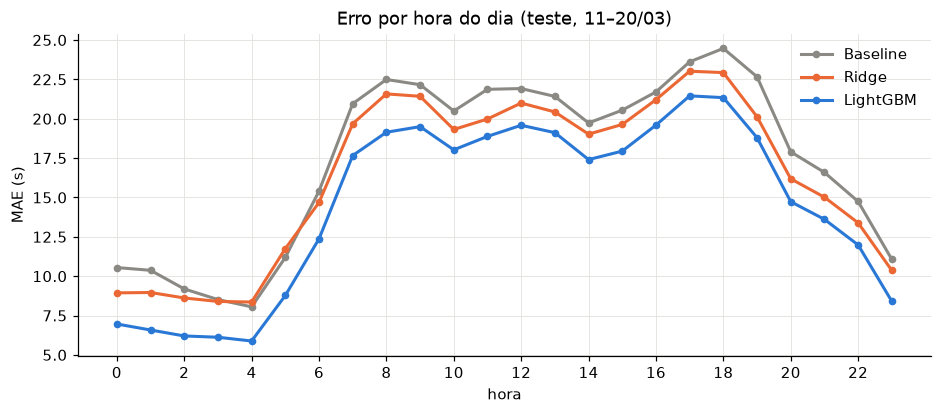

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
erro_Baseline,10.5,10.4,9.2,8.5,8.1,11.2,15.4,21.0,22.5,22.2,...,19.7,20.5,21.7,23.6,24.5,22.7,17.9,16.6,14.7,11.1
erro_Ridge,8.9,9.0,8.6,8.4,8.4,11.7,14.7,19.7,21.6,21.4,...,19.0,19.6,21.2,23.0,22.9,20.1,16.2,15.0,13.4,10.4
erro_LightGBM,7.0,6.6,6.2,6.1,5.9,8.8,12.4,17.7,19.1,19.5,...,17.4,17.9,19.6,21.5,21.3,18.8,14.7,13.6,12.0,8.4


In [12]:
predictions = pd.DataFrame({
    "real": y_test,
    "Baseline": baseline.predict(X_test),
    "Ridge": best_ridge.predict(ridge_models[best_ridge_name][1]),
    "LightGBM": lgbm.predict(X_test),
    "hour": X_test["hour"].astype(int),
    "is_weekend": X_test["is_weekend"].astype(int),
    "date": pd.to_datetime(test.loc[X_test.index, "service_date"]),
})
MODELS = {"Baseline": GRAY, "Ridge": ORANGE, "LightGBM": BLUE}
for name in MODELS:
    predictions[f"erro_{name}"] = (predictions[name] - predictions["real"]).abs()
ERROR_COLUMNS = [f"erro_{name}" for name in MODELS]

by_hour = predictions.groupby("hour")[ERROR_COLUMNS].mean()
fig, ax = plt.subplots(figsize=(10, 3.8))
for name, color in MODELS.items():
    ax.plot(by_hour.index, by_hour[f"erro_{name}"], color=color, lw=2, marker="o", ms=4, label=name)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hora"); ax.set_ylabel("MAE (s)")
ax.set_title("Erro por hora do dia (teste, 11–20/03)")
ax.legend(frameon=False)
plt.show()
by_hour.round(1).T

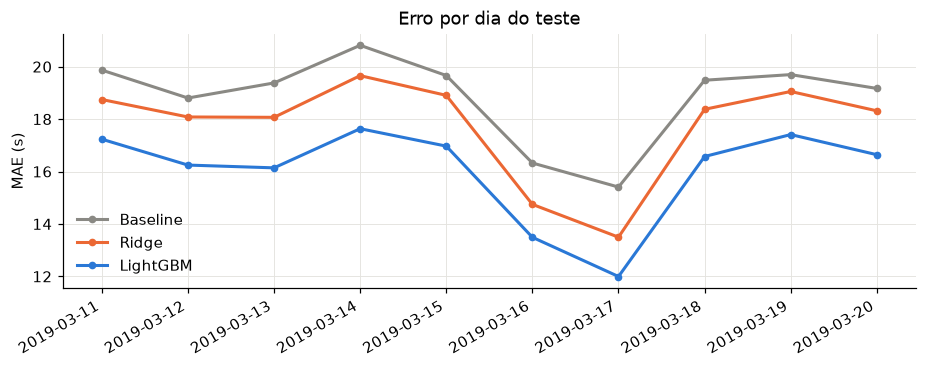

erro_Baseline  erro_Ridge  erro_LightGBM  \
tipo          pico                                                     
dia útil      pico 17–19h           24.55       22.98          21.40   
              resto do dia          18.75       17.91          16.08   
fim de semana pico 17–19h           17.96       16.32          15.34   
              resto do dia          15.51       13.78          12.34   

                            ganho LightGBM vs. baseline (%)  
tipo          pico                                           
dia útil      pico 17–19h                             12.83  
              resto do dia                            14.23  
fim de semana pico 17–19h                             14.58  
              resto do dia                            20.41

In [13]:
by_day = predictions.groupby("date")[ERROR_COLUMNS].mean()
fig, ax = plt.subplots(figsize=(10, 3.4))
for name, color in MODELS.items():
    ax.plot(by_day.index, by_day[f"erro_{name}"], color=color, lw=2, marker="o", ms=4, label=name)
ax.set_ylabel("MAE (s)")
ax.set_title("Erro por dia do teste")
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.show()

summary = predictions.assign(
    tipo=np.where(predictions["is_weekend"] == 1, "fim de semana", "dia útil"),
    pico=np.where(predictions["hour"].between(17, 19), "pico 17–19h", "resto do dia"),
).groupby(["tipo", "pico"])[ERROR_COLUMNS].mean()
summary["ganho LightGBM vs. baseline (%)"] = 100 * (1 - summary["erro_LightGBM"] / summary["erro_Baseline"])
summary

**Leitura.** O erro de todos os modelos segue a curva de lentidão da EDA: baixo de madrugada e alto entre 7h e 19h, com o máximo no pico da tarde. Onde o trânsito varia mais, prever é mais difícil. O LightGBM tem o menor erro em todas as horas.

**Referência:** o erro de medição do próprio pipeline (holdout de pings) é de ~25 s por horário interpolado. Os modelos ficam abaixo disso, então parte do erro que resta é ruído da medição e não do modelo; refinar muito além daqui tem retorno pequeno.

## 6. Experimento extra: um modelo por grupo ou um modelo único?

A pergunta do plano é se **um modelo por linha** de ônibus é melhor que um único modelo global. Enquanto a base V1 (5 linhas) não é gerada, fazemos o mesmo experimento com o agrupamento que já existe na linha 415: o **sentido** (Leblon ou Usina), que são dois trajetos diferentes.

- **Global:** um LightGBM treinado com os dois sentidos (o da seção 4).
- **Separado:** um LightGBM para cada sentido, treinado só com os dados dele.

> Quando a V1 existir, basta trocar `GROUP` por `"line"` nesta célula.

In [14]:
GROUP = "direction"

group_train, group_val, group_test = (part.loc[X.index, GROUP]
                                      for part, X in [(train, X_train), (val, X_val), (test, X_test)])
rows = []
separate_prediction = pd.Series(np.nan, index=X_test.index)
for value in sorted(group_train.unique()):
    tr, va, te = group_train == value, group_val == value, group_test == value
    model, _ = fit_lgbm(X_train[tr], y_train[tr], X_val[va], y_val[va], "l1")
    separate_prediction[te] = model.predict(X_test[te])
    rows.append({
        GROUP: value, "trechos de treino": int(tr.sum()), "trechos de teste": int(te.sum()),
        "MAE global (s)": (predictions.loc[te, "LightGBM"] - y_test[te]).abs().mean(),
        "MAE separado (s)": (separate_prediction[te] - y_test[te]).abs().mean(),
    })
rows.append({
    GROUP: "todos", "trechos de treino": len(X_train), "trechos de teste": len(X_test),
    "MAE global (s)": predictions["erro_LightGBM"].mean(),
    "MAE separado (s)": (separate_prediction - y_test).abs().mean(),
})
comparison = pd.DataFrame(rows).set_index(GROUP)
comparison["diferença (s)"] = comparison["MAE separado (s)"] - comparison["MAE global (s)"]
comparison

,trechos de treino,trechos de teste,MAE global (s),MAE separado (s),diferença (s)
direction,,,,,
Leblon,80412,24842,13.78,13.68,-0.11
Usina,173407,54076,17.53,17.62,0.09
todos,253819,78918,16.35,16.38,0.03


**Leitura.** Os dois arranjos empatam (diferença de centésimos de segundo no total). O modelo global já recebe o sentido como feature e as árvores conseguem separar os dois trajetos sozinhas, então especializar não traz ganho; em compensação, também não há perda por juntar. Para sentidos, vale o modelo único, que é mais simples de manter. Com linhas diferentes o resultado pode mudar, porque linhas pequenas têm poucos dados próprios e podem se beneficiar do que o modelo aprende nas grandes.

## Conclusões da P1

- **LightGBM (L1)** é o melhor modelo desta parte: MAE de ~16,4 s por trecho no teste, cerca de 15% abaixo do baseline.
- **Ridge** fica cerca de 5% abaixo do baseline com one-hot de trecho e de hora × tipo de dia e alvo em log; sem o log, empata. O limite dele é a linearidade, não a regularização.
- O ganho sobre o baseline vem das features de **trânsito em tempo real**. Sem elas, o LightGBM fica atrás da mediana histórica.
- O erro acompanha o relógio: é maior nas horas de mais trânsito, com o máximo no pico da tarde.
- Um modelo por sentido não é melhor que um modelo único.